# Practice Activity 10-2: Penalized regression
**Nicolas Ramel**  
GSB 5544 · Loans data

The response is `interest_rate`. I compare Ridge, LASSO, and Elastic Net, tune their penalties with `GridSearchCV`, and select a final model using training-set cross-validation. The held-out test RMSE is reported at the end.

## What is being predicted?

This is a **pricing-aware estimate of the recorded rate**, assuming that the lender has already assigned a loan grade and subgrade. `sub_grade` is a strong pricing proxy, so a small prediction error here does not mean that the model can assess a new applicant without the lender's grading process.

I leave out `installment`, which depends on the interest rate, and `loan_status`, `balance`, and all `paid_*` fields, which describe payment outcomes. The exported row number is not a predictor. I also omit the free-text job title rather than treating thousands of job descriptions as separate categories.

Sources: [course CSV](https://github.com/kevindavisross/data301/blob/a9ecf060bcb2fafd8d621314904676d2ad80614a/data/loans_full_schema.csv) and [OpenIntro data dictionary](https://openintrostat.github.io/openintro/reference/loans_full_schema.html). The course file contains loans actually made, not all loan applications.

In [1]:
import os
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

import hashlib
import io
import platform
import time
import urllib.request
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from threadpoolctl import threadpool_limits

SEED = 42
pd.set_option("display.max_rows", 80)
pd.set_option("display.max_columns", 12)
pd.set_option("display.float_format", "{:.6f}".format)
plt.rcParams.update({"figure.figsize": (9, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 110})
print(f"Python {platform.python_version()} | pandas {pd.__version__} | "
      f"NumPy {np.__version__} | scikit-learn {sklearn.__version__}")

Python 3.14.6 | pandas 3.0.3 | NumPy 2.4.6 | scikit-learn 1.9.0


In [2]:
DATA_URL = ("https://raw.githubusercontent.com/kevindavisross/data301/"
            "a9ecf060bcb2fafd8d621314904676d2ad80614a/data/loans_full_schema.csv")
with urllib.request.urlopen(DATA_URL) as response:
    csv_bytes = response.read()
data_hash = hashlib.sha256(csv_bytes).hexdigest()
assert data_hash == "94a859d9612c62c74c574ca6e524459515f70bd6b3cc25baacf3f834550c9847"
df = pd.read_csv(io.BytesIO(csv_bytes))
assert df["interest_rate"].notna().all()

X = df.drop(columns="interest_rate")
y = df["interest_rate"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED
)
cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
print(f"Training: {len(X_train):,} loans; untouched test: {len(X_test):,} loans")
print("CSV SHA-256:", data_hash)

Training: 8,000 loans; untouched test: 2,000 loans
CSV SHA-256: 94a859d9612c62c74c574ca6e524459515f70bd6b3cc25baacf3f834550c9847


## A quick look at the training loans

The test split stays closed while I explore the data and compare models. Rates are stored as percentages: an error of 1.0 means **one percentage point**, not a 1% relative error.

,Training interest rate
count,8000.000000
mean,12.416961
std,4.963373
min,5.310000
25%,9.430000
50%,11.980000
75%,15.050000
max,30.940000


,Missing (%)
verification_income_joint,85.312500
annual_income_joint,84.937500
debt_to_income_joint,84.937500
months_since_90d_late,76.937500
months_since_last_delinq,56.862500
months_since_last_credit_inquiry,12.562500
emp_title,8.062500
emp_length,7.950000
num_accounts_120d_past_due,3.437500
debt_to_income,0.212500


,count,mean,std
sub_grade,,,
A1,328,5.315457,0.004987
A2,382,6.075654,0.006272
A3,397,6.716222,0.004855
A4,460,7.345783,0.004944
A5,388,7.965696,0.004958
B1,509,9.435678,0.004959
B2,504,9.926091,0.004884
B3,437,10.416590,0.004746
B4,476,10.905378,0.004991


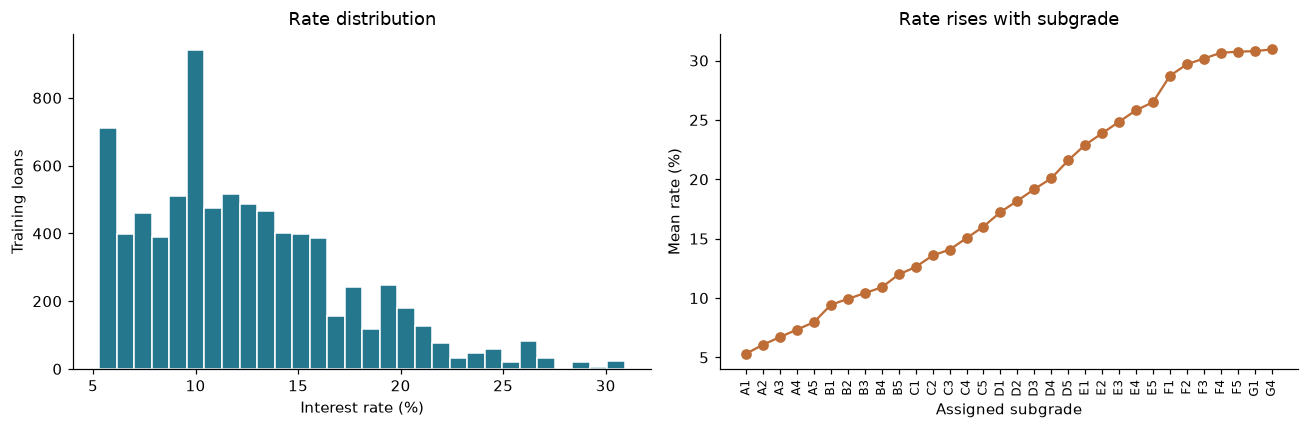

In [3]:
train_view = X_train.assign(interest_rate=y_train)
display(y_train.describe().to_frame("Training interest rate"))
missing = X_train.isna().mean().sort_values(ascending=False)
display((100 * missing[missing > 0]).rename("Missing (%)").to_frame())
display(train_view.groupby("sub_grade")["interest_rate"].agg(
    count="count", mean="mean", std="std"
))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(y_train, bins=30, color="#24778d", edgecolor="white")
axes[0].set(xlabel="Interest rate (%)", ylabel="Training loans", title="Rate distribution")
subgrade_means = train_view.groupby("sub_grade")["interest_rate"].mean()
axes[1].plot(subgrade_means.index, subgrade_means.values, "o-", color="#be6d36")
axes[1].tick_params(axis="x", rotation=90, labelsize=8)
axes[1].set(xlabel="Assigned subgrade", ylabel="Mean rate (%)", title="Rate rises with subgrade")
plt.tight_layout()
plt.show()

Subgrade separates the rates very strongly. Some subgrades are rare, so I retain the broader `grade` as well; it can help when a CV fold has not seen a particular subgrade. Joint-application fields have substantial missingness. Dropping all incomplete rows would discard most of the data, so the pipelines will impute them instead. I keep the observed rate exceptions rather than deleting cases just because they do not follow the usual subgrade pattern.

## Two feature sets, same folds

The smaller set describes the lender's pricing category, issue month, and term. The larger set adds the other available origination and credit-history variables. This checks whether the extra variables improve prediction enough to justify the added model size.

In [4]:
excluded = ["Unnamed: 0", "emp_title", "installment", "loan_status", "balance",
            "paid_total", "paid_principal", "paid_interest", "paid_late_fees"]
feature_sets = {
    "Pricing variables": ["grade", "sub_grade", "issue_month", "term"],
    "Origination + pricing": [c for c in X_train.columns if c not in excluded],
}
for name, columns in feature_sets.items():
    print(f"\n{name} ({len(columns)} original variables):")
    print(", ".join(columns))

def make_pipeline(columns, estimator):
    numeric = X_train[columns].select_dtypes(include=np.number).columns.tolist()
    categorical = [c for c in columns if c not in numeric]
    preprocessing = ColumnTransformer([
        ("numeric", SimpleImputer(strategy="median", add_indicator=True,
                                 keep_empty_features=True), numeric),
        ("categorical", Pipeline([
            ("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
            ("encode", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
        ]), categorical),
    ])
    return Pipeline([
        ("preprocess", preprocessing),
        ("scale", StandardScaler()),
        ("model", estimator),
    ])


Pricing variables (4 original variables):
grade, sub_grade, issue_month, term

Origination + pricing (46 original variables):
emp_length, state, homeownership, annual_income, verified_income, debt_to_income, annual_income_joint, verification_income_joint, debt_to_income_joint, delinq_2y, months_since_last_delinq, earliest_credit_line, inquiries_last_12m, total_credit_lines, open_credit_lines, total_credit_limit, total_credit_utilized, num_collections_last_12m, num_historical_failed_to_pay, months_since_90d_late, current_accounts_delinq, total_collection_amount_ever, current_installment_accounts, accounts_opened_24m, months_since_last_credit_inquiry, num_satisfactory_accounts, num_accounts_120d_past_due, num_accounts_30d_past_due, num_active_debit_accounts, total_debit_limit, num_total_cc_accounts, num_open_cc_accounts, num_cc_carrying_balance, num_mort_accounts, account_never_delinq_percent, tax_liens, public_record_bankrupt, loan_purpose, application_type, loan_amount, term, grade, s

Imputation, one-hot encoding, and standardisation are fitted **inside each training fold**. I scale both the numerical and encoded columns so the penalty is applied on a comparable scale. Median-imputation indicators allow the model to distinguish missing numeric values from an observed median.

### Reference models

These provide a check on whether penalized modeling helps. Every CV result below is the mean of the five fold RMSEs; lower is better. The standard deviation describes variation across folds, not a test-set confidence interval.

In [5]:
baseline_rows = []
with threadpool_limits(limits=1):
    dummy_scores = -cross_val_score(
        DummyRegressor(strategy="mean"), np.zeros((len(y_train), 1)), y_train,
        cv=cv, scoring="neg_root_mean_squared_error", n_jobs=2
    )
    baseline_rows.append({"Model": "Predict training mean", "Feature set": "None",
                          "CV RMSE": dummy_scores.mean(), "Fold SD": dummy_scores.std()})
    for feature_name, columns in feature_sets.items():
        scores = -cross_val_score(
            make_pipeline(columns, LinearRegression()), X_train[columns], y_train,
            cv=cv, scoring="neg_root_mean_squared_error", n_jobs=2
        )
        baseline_rows.append({"Model": "Unpenalized linear regression", "Feature set": feature_name,
                              "CV RMSE": scores.mean(), "Fold SD": scores.std()})
baseline_results = pd.DataFrame(baseline_rows)
display(baseline_results)

,Model,Feature set,CV RMSE,Fold SD
0,Predict training mean,None,4.962498,0.104518
1,Unpenalized linear regression,Pricing variables,0.213411,0.120021
2,Unpenalized linear regression,Origination + pricing,0.215829,0.118009


## Tuning Ridge, LASSO and Elastic Net

Ridge shrinks coefficients with an L2 penalty. LASSO uses an L1 penalty and can make coefficients exactly zero. Elastic Net mixes both penalties. Scikit-learn calls the penalty strength `alpha`; its numeric scale differs between Ridge and the other two estimators, so equal alphas are not equal amounts of regularization.

I search the grids below for both feature sets. `l1_ratio` determines how much of Elastic Net's penalty is L1. All comparisons use the same five folds. The test split is not passed to any search.

An initial search with alpha as small as 0.0001 and solver tolerance 1e-6 was stopped before any test evaluation: nearly unregularized, collinear candidates were taking a long time and some reached the iteration limit. The completed search below uses alpha ≥0.001 for LASSO/Elastic Net and the usual 1e-4 tolerance. This changes numerical fitting settings, not the train/test split. The final choice is checked directly for convergence.

In [6]:
specifications = {
    "Ridge": (Ridge(), {"model__alpha": [0.01, 0.1, 1, 10, 100, 1000]}),
    "LASSO": (Lasso(max_iter=10000, tol=1e-4, selection="cyclic"),
              {"model__alpha": [0.001, 0.01, 0.1, 1]}),
    "Elastic Net": (ElasticNet(max_iter=10000, tol=1e-4, selection="cyclic"),
                    {"model__alpha": [0.001, 0.01, 0.1, 1],
                     "model__l1_ratio": [0.1, 0.5, 0.9]}),
}
searches = {}
summary_rows = []
grid_tables = []
search_started = time.perf_counter()
with threadpool_limits(limits=1):
    for feature_name, columns in feature_sets.items():
        for family, (estimator, parameter_grid) in specifications.items():
            search = GridSearchCV(
                make_pipeline(columns, estimator), parameter_grid, cv=cv,
                scoring="neg_root_mean_squared_error", n_jobs=2,
                refit=True, error_score="raise", return_train_score=False
            )
            search.fit(X_train[columns], y_train)
            searches[(feature_name, family)] = search
            best_index = search.best_index_
            summary_rows.append({
                "Feature set": feature_name, "Model": family,
                "Best alpha": search.best_params_["model__alpha"],
                "Best l1_ratio": search.best_params_.get("model__l1_ratio", np.nan),
                "CV RMSE": -search.best_score_,
                "Fold SD": search.cv_results_["std_test_score"][best_index],
            })
            grid = pd.DataFrame(search.cv_results_)
            grid_tables.append(pd.DataFrame({
                "Feature set": feature_name, "Model": family,
                "alpha": grid["param_model__alpha"].astype(float),
                "l1_ratio": grid["param_model__l1_ratio"].astype(float)
                            if "param_model__l1_ratio" in grid else np.nan,
                "CV RMSE": -grid["mean_test_score"],
                "Fold SD": grid["std_test_score"],
            }))
            print(f"{feature_name} / {family}: best CV RMSE = {-search.best_score_:.6f}")

comparison = pd.DataFrame(summary_rows).sort_values("CV RMSE").reset_index(drop=True)
all_grid_results = pd.concat(grid_tables, ignore_index=True)
display(comparison)
print(f"Grid search completed in {time.perf_counter() - search_started:.1f} seconds.")

Pricing variables / Ridge: best CV RMSE = 0.213411


Pricing variables / LASSO: best CV RMSE = 0.180170


Pricing variables / Elastic Net: best CV RMSE = 0.183377


Origination + pricing / Ridge: best CV RMSE = 0.215829


Origination + pricing / LASSO: best CV RMSE = 0.181949


Origination + pricing / Elastic Net: best CV RMSE = 0.185070


,Feature set,Model,Best alpha,Best l1_ratio,CV RMSE,Fold SD
0,Pricing variables,LASSO,0.001000,NaN,0.180170,0.130012
1,Origination + pricing,LASSO,0.001000,NaN,0.181949,0.128799
2,Pricing variables,Elastic Net,0.001000,0.900000,0.183377,0.127547
3,Origination + pricing,Elastic Net,0.001000,0.900000,0.185070,0.126397
4,Pricing variables,Ridge,0.010000,NaN,0.213411,0.120021
5,Origination + pricing,Ridge,0.010000,NaN,0.215829,0.118009


Grid search completed in 37.5 seconds.


,Feature set,Model,alpha,l1_ratio,CV RMSE,Fold SD
0,Origination + pricing,Elastic Net,0.001000,0.100000,0.215577,0.117938
1,Origination + pricing,Elastic Net,0.001000,0.500000,0.204799,0.117709
2,Origination + pricing,Elastic Net,0.001000,0.900000,0.185070,0.126397
3,Origination + pricing,Elastic Net,0.010000,0.100000,0.218956,0.115767
4,Origination + pricing,Elastic Net,0.010000,0.500000,0.216701,0.115430
5,Origination + pricing,Elastic Net,0.010000,0.900000,0.200317,0.116833
6,Origination + pricing,Elastic Net,0.100000,0.100000,0.364206,0.065233
7,Origination + pricing,Elastic Net,0.100000,0.500000,0.407121,0.057249
8,Origination + pricing,Elastic Net,0.100000,0.900000,0.494019,0.043248
9,Origination + pricing,Elastic Net,1.000000,0.100000,1.720197,0.048520


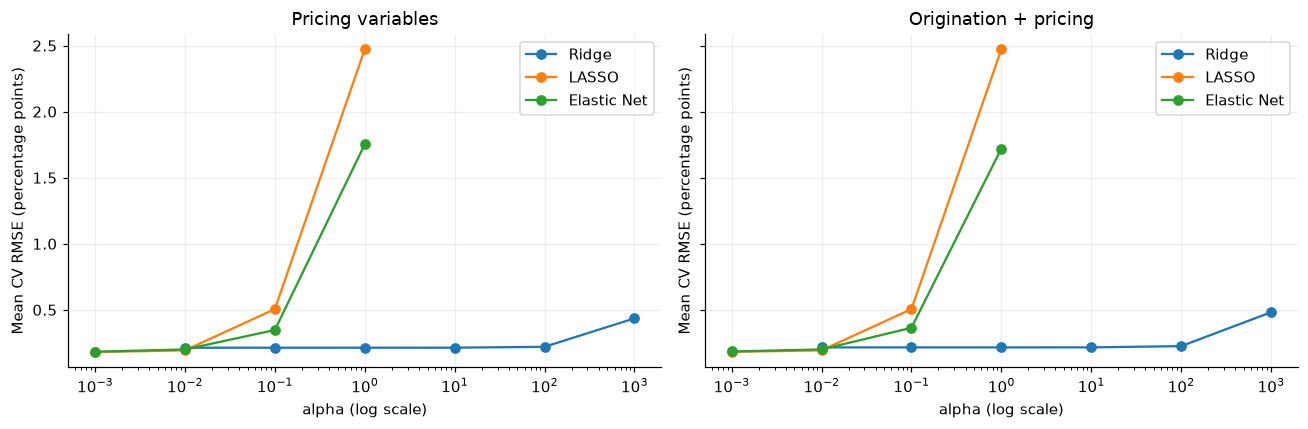

In [7]:
# Full tuning record, rather than just the winning setting.
display(all_grid_results.sort_values(["Feature set", "Model", "alpha", "l1_ratio"]).reset_index(drop=True))

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, feature_name in zip(axes, feature_sets):
    subset = all_grid_results[all_grid_results["Feature set"] == feature_name]
    for family in specifications:
        curve = subset[subset["Model"] == family].groupby("alpha")["CV RMSE"].min()
        ax.semilogx(curve.index, curve.values, marker="o", label=family)
    ax.set(xlabel="alpha (log scale)", ylabel="Mean CV RMSE (percentage points)", title=feature_name)
    ax.grid(alpha=0.2)
    ax.legend()
plt.tight_layout()
plt.show()

For Elastic Net, the curve shows the best `l1_ratio` at each alpha; the table contains every pair that was tried. The grids were specified before the test evaluation. This is a finite search, not a claim that every possible model or penalty has been checked.

### How sparse are the fitted models?

Counts refer to the encoded/imputed feature columns, rather than the original variables. A categorical variable can contribute several coefficients. The values shown are from each search's best model, refitted on all 8,000 training loans.

In [8]:
sparsity_rows = []
for (feature_name, family), search in searches.items():
    coefficients = search.best_estimator_.named_steps["model"].coef_
    sparsity_rows.append({
        "Feature set": feature_name, "Model": family,
        "Encoded columns": len(coefficients),
        "Exactly zero": int(np.count_nonzero(coefficients == 0)),
        "Nonzero": int(np.count_nonzero(coefficients != 0)),
    })
display(pd.DataFrame(sparsity_rows))

# Lock the selected family, feature set and hyperparameters using CV only.
winner = comparison.iloc[0]
winning_key = (winner["Feature set"], winner["Model"])
final_search = searches[winning_key]
final_model = final_search.best_estimator_
final_features = feature_sets[winning_key[0]]

feature_names = final_model.named_steps["preprocess"].get_feature_names_out()
coefficient_table = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient (scaled inputs)": final_model.named_steps["model"].coef_
})
display(coefficient_table.assign(abs_coefficient=lambda x: x.iloc[:, 1].abs())
        .sort_values("abs_coefficient", ascending=False).drop(columns="abs_coefficient").head(15))
display(Markdown(
    f"**CV selection:** {winning_key[1]}, using **{winning_key[0]}**. "
    f"Mean CV RMSE: **{-final_search.best_score_:.6f} percentage points**. "
    f"Selected parameters: `{final_search.best_params_}`."
))

,Feature set,Model,Encoded columns,Exactly zero,Nonzero
0,Pricing variables,Ridge,43,0,43
1,Pricing variables,LASSO,43,9,34
2,Pricing variables,Elastic Net,43,8,35
3,Origination + pricing,Ridge,163,1,162
4,Origination + pricing,LASSO,163,79,84
5,Origination + pricing,Elastic Net,163,73,90


,Feature,Coefficient (scaled inputs)
1,categorical__grade_A,-2.890861
5,categorical__grade_E,1.774244
2,categorical__grade_B,-1.460679
4,categorical__grade_D,1.439512
6,categorical__grade_F,1.046194
27,categorical__sub_grade_D5,0.534516
7,categorical__grade_G,0.527915
22,categorical__sub_grade_C5,0.415571
8,categorical__sub_grade_A1,-0.401214
13,categorical__sub_grade_B1,-0.357074


**CV selection:** LASSO, using **Pricing variables**. Mean CV RMSE: **0.180170 percentage points**. Selected parameters: `{'model__alpha': 0.001}`.

### Check on the selected solver

I verify the locked winner's numerical convergence before looking at the test error. For LASSO or Elastic Net this also checks the five refitted CV folds. This is a check of the same settings, not another parameter search.

In [9]:
from sklearn.base import clone
from sklearn.model_selection import cross_validate

selected_estimator = final_model.named_steps["model"]
if isinstance(selected_estimator, Ridge):
    print("The selected Ridge model uses a direct linear-algebra solver, not coordinate descent.")
else:
    with threadpool_limits(limits=1):
        checked_cv = cross_validate(
            clone(final_model), X_train[final_features], y_train, cv=cv,
            scoring="neg_root_mean_squared_error", return_estimator=True,
            n_jobs=1, error_score="raise"
        )
    convergence_rows = []
    for fold_number, ((fit_indices, _), fitted_pipeline) in enumerate(
        zip(cv.split(X_train), checked_cv["estimator"]), start=1
    ):
        fitted = fitted_pipeline.named_steps["model"]
        bound = fitted.tol * np.var(y_train.iloc[fit_indices])
        convergence_rows.append({
            "Fit": f"CV fold {fold_number}", "Iterations": fitted.n_iter_,
            "Duality gap": fitted.dual_gap_, "Tolerance bound": bound,
            "Converged": fitted.n_iter_ < fitted.max_iter and fitted.dual_gap_ <= 1.01 * bound,
        })
    bound = selected_estimator.tol * np.var(y_train)
    convergence_rows.append({
        "Fit": "Full training refit", "Iterations": selected_estimator.n_iter_,
        "Duality gap": selected_estimator.dual_gap_, "Tolerance bound": bound,
        "Converged": selected_estimator.n_iter_ < selected_estimator.max_iter
                     and selected_estimator.dual_gap_ <= 1.01 * bound,
    })
    convergence_check = pd.DataFrame(convergence_rows)
    display(convergence_check)
    assert convergence_check["Converged"].all(), "Selected model needs additional solver iterations."
    assert np.isclose(-checked_cv["test_score"].mean(), -final_search.best_score_, rtol=1e-5)
    print(f"Verified mean CV RMSE: {-checked_cv['test_score'].mean():.6f}")

,Fit,Iterations,Duality gap,Tolerance bound,Converged
0,CV fold 1,1293,0.000941,0.002425,True
1,CV fold 2,1372,0.000953,0.002502,True
2,CV fold 3,1318,0.000962,0.002465,True
3,CV fold 4,1297,0.001020,0.002476,True
4,CV fold 5,1304,0.000939,0.002447,True
5,Full training refit,1316,0.000985,0.002463,True


Verified mean CV RMSE: 0.180170


## Final test evaluation

The selection above is now fixed. I use the chosen estimator to predict the 2,000 held-out loans once. The extra diagnostics below describe that same prediction vector; they are not used to choose another model.

,Metric,Value
0,Test RMSE (percentage points),0.073158
1,Test MAE (percentage points),0.044946
2,Test R-squared,0.999798


Final original features: grade, sub_grade, issue_month, term
Final parameters: {'model__alpha': 0.001}


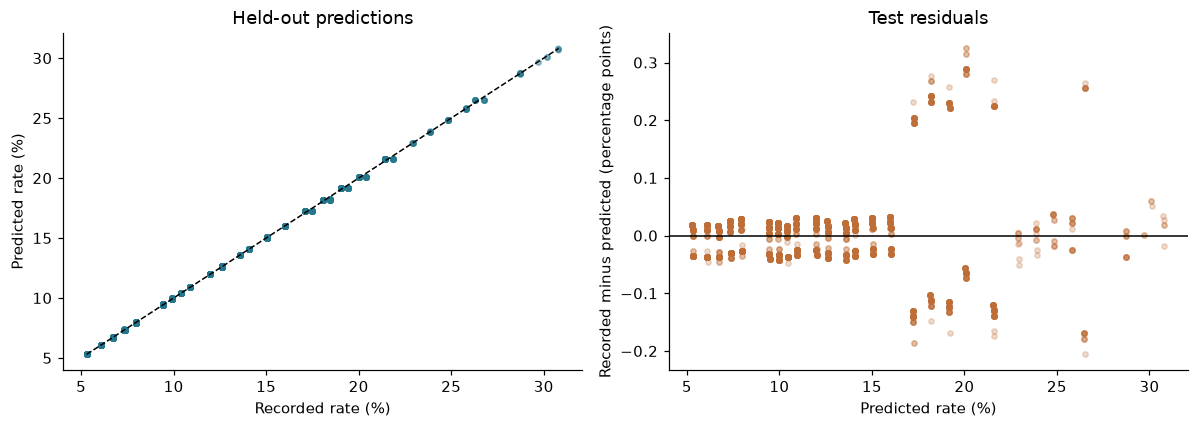

In [10]:
test_predictions = final_model.predict(X_test[final_features])
test_rmse = root_mean_squared_error(y_test, test_predictions)
test_mae = mean_absolute_error(y_test, test_predictions)
test_r2 = r2_score(y_test, test_predictions)
display(pd.DataFrame({
    "Metric": ["Test RMSE (percentage points)", "Test MAE (percentage points)", "Test R-squared"],
    "Value": [test_rmse, test_mae, test_r2],
}))
print("Final original features:", ", ".join(final_features))
print("Final parameters:", final_search.best_params_)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(y_test, test_predictions, s=12, alpha=0.25, color="#24778d")
limits = [min(y_test.min(), test_predictions.min()), max(y_test.max(), test_predictions.max())]
axes[0].plot(limits, limits, "--", color="black", linewidth=1)
axes[0].set(xlabel="Recorded rate (%)", ylabel="Predicted rate (%)", title="Held-out predictions")
axes[1].scatter(test_predictions, y_test - test_predictions, s=12, alpha=0.25, color="#be6d36")
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set(xlabel="Predicted rate (%)", ylabel="Recorded minus predicted (percentage points)", title="Test residuals")
plt.tight_layout()
plt.show()

In [11]:
display(Markdown(f"""
### Final result — Nicolas Ramel

- **Selected model:** {winning_key[1]} with {winning_key[0].lower()}.
- **Hyperparameters:** `{final_search.best_params_}`.
- **Mean five-fold CV RMSE:** {-final_search.best_score_:.6f} percentage points.
- **Held-out test RMSE:** **{test_rmse:.6f} percentage points**.

The final choice follows the lowest mean CV RMSE among the six penalized-model searches, rather than the smallest training error. The test result is a separate estimate of prediction error for similar loans.

This modelling exercise benefits heavily from the lender's assigned grade and subgrade. It is useful for estimating a recorded rate when that information is already available; it does not establish performance for ungraded loan applications. Rare subgrades, source-data exceptions, and a different lending period could change the error.
"""))


### Final result — Nicolas Ramel

- **Selected model:** LASSO with pricing variables.
- **Hyperparameters:** `{'model__alpha': 0.001}`.
- **Mean five-fold CV RMSE:** 0.180170 percentage points.
- **Held-out test RMSE:** **0.073158 percentage points**.

The final choice follows the lowest mean CV RMSE among the six penalized-model searches, rather than the smallest training error. The test result is a separate estimate of prediction error for similar loans.

This modelling exercise benefits heavily from the lender's assigned grade and subgrade. It is useful for estimating a recorded rate when that information is already available; it does not establish performance for ungraded loan applications. Rare subgrades, source-data exceptions, and a different lending period could change the error.


### Re-running the analysis

Run the cells from top to bottom in a Python notebook environment (including Colab) with pandas, NumPy, matplotlib and a recent scikit-learn (`>=1.4`). The data URL is pinned to a specific course-repository commit and the SHA-256 check verifies the file. The split and CV folds use seed 42. No local data files are required.